# Laboratorio 4 - Segmentación de imágenes con técnicas de agrupación
### Caso DermAlpes

**Integrantes:**
- Samuel Molina Luna
- Daniel Pardo Pardo

## Descripción del laboratorio

**DermAlpes** es una empresa de telemedicina que conecta centros de salud de municipios pequeños con dermatólogos de las ciudades principales. En los centros de salud se toman fotografías de lesiones de piel con un dermatoscopio y se envían para que un especialista las revise a distancia. Para agilizar esa revisión, la empresa quiere una herramienta que **delimite automáticamente la zona de la lesión** en cada imagen, de modo que el dermatólogo pueda medir su tamaño y su forma y concentrar su atención en la región relevante.

DermAlpes no cuenta con imágenes etiquetadas de sus propios pacientes, así que como primera aproximación quiere evaluar si es posible segmentar la lesión **sin entrenar un modelo supervisado**, agrupando los píxeles de la imagen según su **color** y su **posición**. Para validar la idea, se construye un método de segmentación sobre un conjunto de imágenes públicas que sí incluye máscaras de referencia elaboradas por dermatólogos, y así se mide qué tan bien funciona, dónde falla y por qué.

La herramienta **no realiza diagnósticos**: su único propósito es delimitar la lesión como apoyo para el especialista. Aun así, la empresa quiere entender las limitaciones del método y los riesgos de usarlo con pacientes cuyas características difieran de las de las imágenes con que fue construido.

## Conjunto de datos

Para el conjunto de datos se utiliza una selección de 20 imágenes dermatoscópicas de ISIC 2016. Cada imagen viene acompañada de una máscara de referencia que identifica los píxeles correspondientes a la lesión. Estas máscaras no se usan para agrupar los píxeles sino que solo sirven para comparar y evaluar los resultados del método.

Las imágenes se dividen en dos conjuntos:

| Conjunto | Cantidad | Uso |
|---|---|---|
| **Ajuste** | 15 imágenes | Explorar y seleccionar la configuración del método comparando las máscaras estimadas con las de referencia |
| **Prueba** | 5 imágenes | Evaluar el desempeño final sin realizar modificaciones adicionales |

| Imágenes de ajuste | | | Imágenes de prueba |
|---|---|---|---|
| ISIC_0000085 | ISIC_0000114 | ISIC_0000150 | ISIC_0000087 |
| ISIC_0000086 | ISIC_0000116 | ISIC_0000153 | ISIC_0000105 |
| ISIC_0000089 | ISIC_0000122 | ISIC_0000156 | ISIC_0000110 |
| ISIC_0000094 | ISIC_0000133 | ISIC_0000157 | ISIC_0000123 |
| ISIC_0000108 | ISIC_0000137 | ISIC_0000112 | ISIC_0000128 |

**Preparación de las máscaras.** Las máscaras originales contienen los valores 0 (piel o fondo) y 255 (lesión), que se convierten a 0 y 1. Si se reduce el tamaño de las imágenes, las máscaras se redimensionan con interpolación por vecino más cercano para conservar sus valores binarios.

**Fuente.** International Skin Imaging Collaboration (ISIC), *ISIC 2016 Challenge - Task 1: Lesion Segmentation*. Disponible en: https://challenge.isic-archive.com/landing/2016/37/

Referencia del desafío: Gutman, D., Codella, N. C. F., Celebi, E., et al. (2016). *Skin Lesion Analysis toward Melanoma Detection: A Challenge at the International Symposium on Biomedical Imaging (ISBI) 2016, hosted by the International Skin Imaging Collaboration (ISIC)*. arXiv:1605.01397.

# Importación de librerías

Se importan las librerías que se usan a lo largo del laboratorio: NumPy y pandas para los datos y las tablas de resultados, Pillow para leer las imágenes, Matplotlib y Seaborn para las visualizaciones, y Scikit-learn para el pipeline, K-medias y las métricas (silueta, Dice a través de `f1_score`, V-measure, precisión y recall).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2
from glob import glob

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, f1_score, v_measure_score,
                             precision_score, recall_score)

## Pipeline

In [2]:
import os

ids_ajuste = ['ISIC_0000085','ISIC_0000086','ISIC_0000089','ISIC_0000094','ISIC_0000108',
              'ISIC_0000114','ISIC_0000116','ISIC_0000122','ISIC_0000133','ISIC_0000137',
              'ISIC_0000150','ISIC_0000153','ISIC_0000156','ISIC_0000157','ISIC_0000112']
ids_prueba = ['ISIC_0000087','ISIC_0000105','ISIC_0000110','ISIC_0000123','ISIC_0000128']

RUTA_IMAGENES = 'data/imagenes'
RUTA_MASCARAS = 'data/mascaras'

print(len(os.listdir(RUTA_IMAGENES)), 'imágenes')
print(len(os.listdir(RUTA_MASCARAS)), 'máscaras')

faltan = [i for i in ids_ajuste + ids_prueba
          if not os.path.exists(f'{RUTA_IMAGENES}/{i}.jpg')
          or not os.path.exists(f'{RUTA_MASCARAS}/{i}_Segmentation.png')]
print('Faltantes:', faltan)

20 imágenes
20 máscaras
Faltantes: []


## 1. Pipeline de representacion y agrupacion

**1.1 Carga de imagenes y mascaras**

Primero cada imagen se redimensiona para que su lado mayor mida `MAX_LADO` pixeles lo que conserva la proporcion con el fin de reducir el costo de K-means. La mascara tambien se redimensiona al mismo tamaño con interpolacion de vecino mas cercano para no crear valores intermedios y se convierte de 0/255 a 0/1 (1 = lesion).

In [3]:
MAX_LADO = 128

def cargar_par(id_img, max_lado=MAX_LADO):
    img = cv2.imread(f'{RUTA_IMAGENES}/{id_img}.jpg', cv2.IMREAD_COLOR_RGB)
    mask = cv2.imread(f'{RUTA_MASCARAS}/{id_img}_Segmentation.png', cv2.IMREAD_GRAYSCALE)
    factor = max_lado / max(img.shape[:2])
    nuevo = (round(img.shape[1] * factor), round(img.shape[0] * factor))  # (ancho, alto)
    img = cv2.resize(img, nuevo, interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, nuevo, interpolation=cv2.INTER_NEAREST)
    return img, (mask > 127).astype(int)

imagenes, mascaras = {}, {}
for id_img in ids_ajuste + ids_prueba:
    imagenes[id_img], mascaras[id_img] = cargar_par(id_img)

resumen = pd.DataFrame({
    'id': list(imagenes.keys()),
    'grupo': ['ajuste'] * len(ids_ajuste) + ['prueba'] * len(ids_prueba),
    'alto': [imagenes[i].shape[0] for i in imagenes],
    'ancho': [imagenes[i].shape[1] for i in imagenes],
    'valores_mascara': [sorted(np.unique(mascaras[i]).tolist()) for i in imagenes],
    '%_lesion': [round(100 * mascaras[i].mean(), 1) for i in imagenes],
})
resumen[resumen['grupo'] == 'ajuste']

,id,grupo,alto,ancho,valores_mascara,%_lesion
0,ISIC_0000085,ajuste,96,128,"[0, 1]",12.7
1,ISIC_0000086,ajuste,96,128,"[0, 1]",23.4
2,ISIC_0000089,ajuste,96,128,"[0, 1]",12.1
3,ISIC_0000094,ajuste,96,128,"[0, 1]",5.9
4,ISIC_0000108,ajuste,96,128,"[0, 1]",18.5
5,ISIC_0000114,ajuste,96,128,"[0, 1]",3.1
6,ISIC_0000116,ajuste,96,128,"[0, 1]",36.1
7,ISIC_0000122,ajuste,96,128,"[0, 1]",39.1
8,ISIC_0000133,ajuste,96,128,"[0, 1]",14.2
9,ISIC_0000137,ajuste,96,128,"[0, 1]",24.4


**1.2 Representacion por pixel y pipeline**

Cada imagen $H \times W \times 3$ se convierte en una matriz de $H \cdot W$ filas (un pixel por fila) con las caracteristicas $[\beta R, \beta G, \beta B, \lambda x, \lambda y]$, donde R, G, B se dividen por 255 y las coordenadas $x, y$ por $W-1$ y $H-1$, de modo que todas queden en $[0, 1]$. Solo importa la razón $\lambda/\beta$, porque K-means depende de las distancias relativas. Con $\lambda = 0$ se usa solo color y con $\beta = 0$ solo posición. Con esto el pipeline tiene dos pasos: la representacion (con β y λ como parametros) y K-means.

Forma de X: (12288, 5)


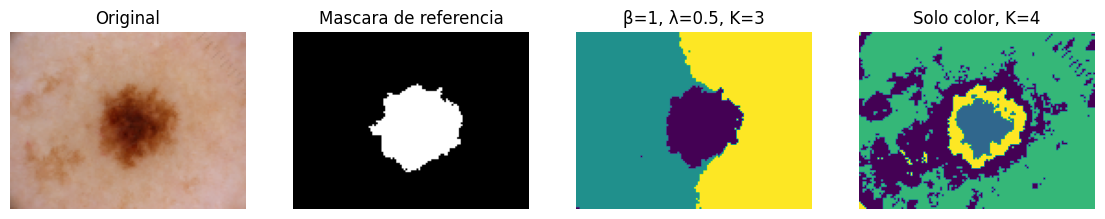

In [4]:
def representar_pixeles(imagen, beta=1.0, lam=1.0):
    alto, ancho, _ = imagen.shape
    color = imagen.reshape(-1, 3) / 255.0
    I, J = np.meshgrid(np.arange(alto), np.arange(ancho), indexing='ij')
    y = I.ravel() / (alto - 1)
    x = J.ravel() / (ancho - 1)
    return np.column_stack([beta * color, lam * x, lam * y])

def construir_pipeline(beta, lam, k, semilla=42):
    return Pipeline(steps=[
        ('representacion', FunctionTransformer(representar_pixeles,
                                               kw_args={'beta': beta, 'lam': lam})),
        ('kmeans', KMeans(n_clusters=k, n_init=10, random_state=semilla))
    ])

# Prueba rápida con una imagen de ajuste
id_demo = 'ISIC_0000085'
img_demo = imagenes[id_demo]

pipe = construir_pipeline(beta=1.0, lam=0.5, k=3)
etiquetas = pipe.fit_predict(img_demo).reshape(img_demo.shape[:2])

# Cambiar β, λ o K sin tocar la implementación
pipe.set_params(representacion__kw_args={'beta': 1.0, 'lam': 0.0}, kmeans__n_clusters=4)
etiquetas_color = pipe.fit_predict(img_demo).reshape(img_demo.shape[:2])

print('Forma de X:', pipe[:-1].transform(img_demo).shape)

fig, ax = plt.subplots(1, 4, figsize=(14, 4))
ax[0].imshow(img_demo);               ax[0].set_title('Original')
ax[1].imshow(mascaras[id_demo], cmap='gray'); ax[1].set_title('Mascara de referencia')
ax[2].imshow(etiquetas);              ax[2].set_title('β=1, λ=0.5, K=3')
ax[3].imshow(etiquetas_color);        ax[3].set_title('Solo color, K=4')
for a in ax: a.axis('off')
plt.show()

## 2. Selección de K con el coeficiente de silueta

Ahora para cada una de las 15 imagenes de ajuste y cada una de 10 combinaciones $(\beta, \lambda)$ se entrena K-means con un valor entre K = 2 y 8 para luego elegir el K con mayor coeficiente de silueta. Como el cálculo exacto de la silueta es costoso este se calcula sobre una muestra aleatoria de 2000 pixeles con semilla 42, que es la misma para todos los K y combinaciones, de modo que los valores son reproducibles y comparables. Como solo importa la razón $\lambda/\beta$, se fija $\beta = 1$ y se varía $\lambda$, salvo en el caso de solo posición ($\beta = 0$, $\lambda = 1$). Las combinaciones son: solo color ($\lambda/\beta = 0$), $\lambda/\beta \in \{0.1, 0.25, 0.5, 0.75, 1, 1.5, 2, 4\}$ y solo posición ($\beta = 0$).

In [5]:
MUESTRA = 2000
SEMILLA = 42
K_VALS = list(range(2, 9))
combos = [(1, 0)] + [(1, r) for r in [0.1, 0.25, 0.5, 0.75, 1, 1.5, 2, 4]] + [(0, 1)]

filas = []
etiquetas_todas = {}   # (id, beta, lam, k) -> etiquetas de cada píxel, se reutilizan luego

pipe = construir_pipeline(beta=1, lam=0, k=2, semilla=SEMILLA)
for id_img in ids_ajuste:
    img = imagenes[id_img]
    for beta, lam in combos:
        pipe.set_params(representacion__kw_args={'beta': beta, 'lam': lam})
        X = pipe[:-1].transform(img)
        for k in K_VALS:
            pipe.set_params(kmeans__n_clusters=k)
            etiquetas = pipe.fit_predict(img)
            sil = silhouette_score(X, etiquetas, sample_size=MUESTRA, random_state=SEMILLA)
            etiquetas_todas[(id_img, beta, lam, k)] = etiquetas.reshape(img.shape[:2])
            filas.append({'id': id_img, 'beta': beta, 'lam': lam,
                          'razon': lam / beta if beta > 0 else np.inf,
                          'k': k, 'silueta': sil})
    print(id_img, 'listo')

resultados_k = pd.DataFrame(filas)
mejor_k = resultados_k.loc[resultados_k.groupby(['id', 'beta', 'lam'])['silueta'].idxmax()]

# Resumen por combinación: K elegido por imagen y silueta promedio
resumen_k = (mejor_k.groupby('razon')
             .agg(k_mediano=('k', 'median'), k_min=('k', 'min'), k_max=('k', 'max'),
                  silueta_media=('silueta', 'mean'))
             .round(3))
resumen_k

ISIC_0000085 listo
ISIC_0000086 listo
ISIC_0000089 listo
ISIC_0000094 listo
ISIC_0000108 listo
ISIC_0000114 listo
ISIC_0000116 listo
ISIC_0000122 listo
ISIC_0000133 listo
ISIC_0000137 listo
ISIC_0000150 listo
ISIC_0000153 listo
ISIC_0000156 listo
ISIC_0000157 listo
ISIC_0000112 listo


,k_mediano,k_min,k_max,silueta_media
razon,,,,
0.00,2.0,2,2,0.749
0.10,2.0,2,2,0.716
0.25,2.0,2,5,0.615
0.50,2.0,2,5,0.491
0.75,5.0,2,6,0.443
1.00,5.0,5,6,0.438
1.50,5.0,4,6,0.431
2.00,5.0,4,6,0.423
4.00,5.0,4,5,0.403


### Resultados de la selección de K

La tabla anterior resume, para cada combinación, el K elegido por la silueta en las 15 imágenes de ajuste. Se distinguen tres comportamientos:

- **Solo color o poco peso de la posición ($\lambda/\beta \leq 0.25$).** La silueta elige K = 2 en prácticamente todas las imágenes y alcanza los valores más altos (entre 0.62 y 0.75). Esto indica que, en el espacio de color, los píxeles forman dos grupos bien separados. Sin embargo, una silueta alta no garantiza que esos dos grupos sean lesión y piel.
- **Peso intermedio y alto de la posición ($0.75 \leq \lambda/\beta \leq 4$).** La mediana de K sube a 5 y la silueta baja a valores entre 0.40 y 0.44. Al dar peso a la posición, K-medias tiende a dividir la imagen en parches espaciales contiguos, y en ese espacio no hay una separación natural tan marcada.
- **Solo posición ($\beta = 0$).** el K que se elige es 4 en todas las imágenes y la silueta es practicamente igual ya que la representacion no contiene información de la imagen sino que solo la geometría como tal del rectangulo.

Los valores de silueta de combinaciones distintas no son comparables entre sí, porque cambia el espacio de características. Por eso la silueta se usa únicamente para elegir K dentro de cada combinación.

In [8]:
# K elegido por la silueta para cada imagen y cada razón λ/β (inf = solo posición)
k_por_imagen = mejor_k.pivot(index='id', columns='razon', values='k')
k_por_imagen

razon,0.00,0.10,0.25,0.50,0.75,1.00,1.50,2.00,4.00,inf
id,,,,,,,,,,
ISIC_0000085,2,2,2,2,5,5,5,5,5,4
ISIC_0000086,2,2,2,2,5,5,5,5,5,4
ISIC_0000089,2,2,2,2,2,5,5,5,5,4
ISIC_0000094,2,2,5,5,5,5,4,4,4,4
ISIC_0000108,2,2,2,2,5,5,5,5,5,4
ISIC_0000112,2,2,2,5,5,5,5,5,4,4
ISIC_0000114,2,2,2,5,5,5,4,4,4,4
ISIC_0000116,2,2,2,5,5,5,5,5,4,4
ISIC_0000122,2,2,2,5,5,5,5,5,4,4


### K elegido en cada imagen

La tabla por imagen muestra cómo cambia K a medida que aumenta el peso de la posición:

- Con $\lambda/\beta \in \{0, 0.1\}$, las 15 imágenes eligen K = 2. Con $\lambda/\beta = 0.25$, lo hacen 14 de 15; la excepción es ISIC_0000094, que pasa a K = 5.
- Con $\lambda/\beta = 0.5$ ocurre la transición: 9 imágenes mantienen K = 2 y 6 saltan a K = 5.
- Con $\lambda/\beta = 1$, todas las imágenes eligen K = 5, salvo ISIC_0000133, que elige K = 6. Con razones mayores, K oscila entre 4 y 6. Con $\lambda/\beta = 4$, 7 de las 15 imágenes ya eligen K = 4, el mismo valor que con solo posición.

Esta mátriz permite, principalmente, confirmar las observaciones hechas a partir de la selección del mejor K para cada combinación $\lambda/\beta$ hecha previamente.

**Consecuencia para la actividad 3:** el K elegido depende mucho de $\lambda/\beta$. Por eso el criterio de construcción de la máscara debe funcionar tanto con K = 2 como con K ≈ 5. Con K ≈ 5, la lesión puede quedar repartida entre varios grupos, o un mismo parche espacial puede mezclar lesión y piel.

## 3. Construcción de la máscara de la lesión

K-medias agrupa los píxeles, pero no indica cuáles corresponden a la lesión. Antes de diseñar un criterio automático para identificarlos, se examina qué representan los grupos obtenidos en la actividad 2. El análisis se hace en dos casos representativos: solo color ($\lambda/\beta = 0$), donde la silueta elige K = 2 en todas las imágenes, y color y posición con igual peso ($\lambda/\beta = 1$), donde elige K = 5 en 14 de las 15 imágenes. Esta inspección usa únicamente las etiquetas de K-medias y las imágenes de ajuste; no se usan las máscaras de referencia ni las imágenes de prueba.

### 3.1 Exploración de los grupos

In [13]:
# Grupos obtenidos con el K elegido por la silueta para una combinación (β, λ).
# Solo se usan las etiquetas de K-medias, no las máscaras de referencia.
def mostrar_grupos(beta, lam, titulo):
    fig, ax = plt.subplots(3, 5, figsize=(16, 8))
    for a, id_img in zip(ax.ravel(), ids_ajuste):
        fila = mejor_k[(mejor_k['id'] == id_img) & (mejor_k['beta'] == beta) & (mejor_k['lam'] == lam)]
        k = int(fila['k'].iloc[0])
        a.imshow(etiquetas_todas[(id_img, beta, lam, k)])
        a.set_title(f'{id_img[-3:]} (K = {k})'); a.axis('off')
    plt.suptitle(titulo)
    plt.show()

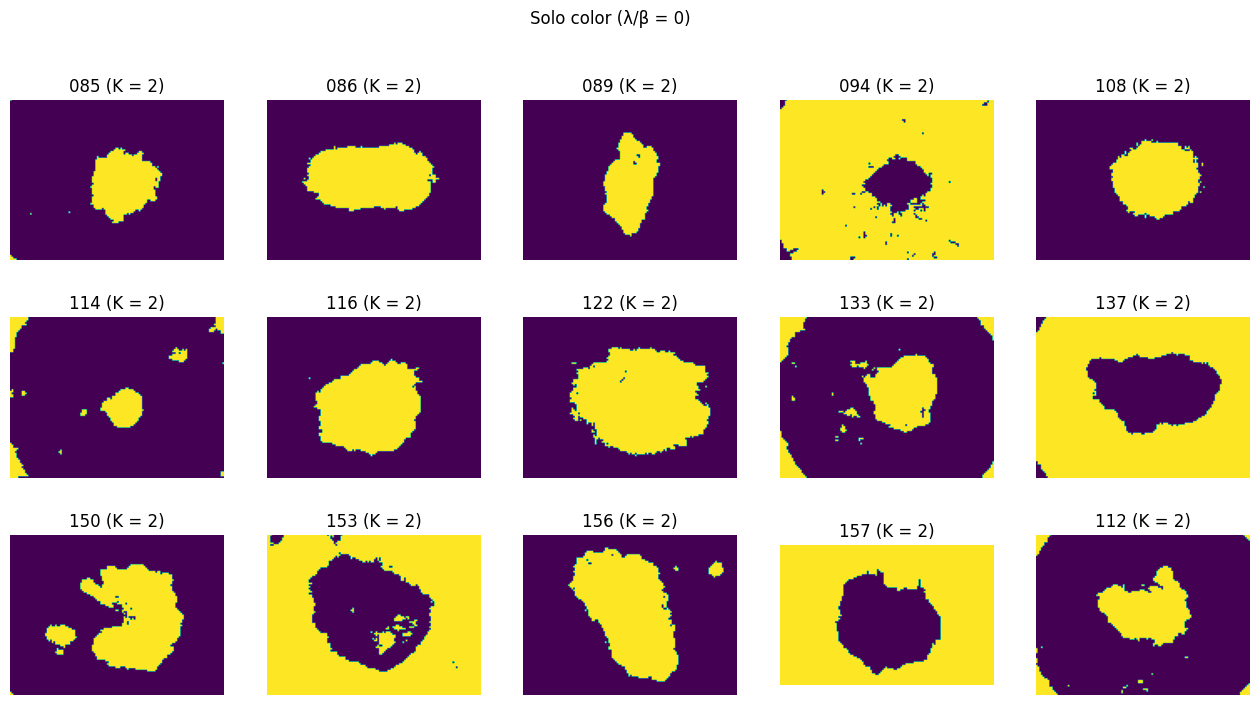

In [14]:
mostrar_grupos(1, 0, 'Solo color (λ/β = 0)')

#### Solo color ($\lambda/\beta = 0$, K = 2)

1. **La lesión siempre queda en uno de los dos grupos.** En todas las imágenes, uno de los grupos contiene una región compacta y aproximadamente central, compatible con la lesión.
2. **Las esquinas oscuras se confunden con la lesión.** En ciertas imágenes (segunda fila primera columna, por ejemplo), las esquinas quedan en el mismo grupo que la lesión. El dermatoscopio oscurece la periferia de la imagen y, en RGB, esas zonas se parecen más a la lesión que a la piel. Si se tomara el grupo completo como máscara, estas esquinas producirían falsos positivos.
3. **El color dentro de la lesión no es homogéneo.** En algunas imágenes (fila 3 columna 2, entre otras), las zonas más claras del interior de la lesión quedan asignadas al grupo de la piel, lo que deja huecos en la región.
4. **Hay regiones separadas de la lesión principal.** En otras imágenes, como la de la fila 3 columna 3, aparecen pequeñas regiones aisladas en el mismo grupo que la lesión. Podrían ser parte de la lesión o no.
5. **El número del grupo es arbitrario.** En algunas imágenes la lesión corresponde al grupo 1 (amarillo) y en otras al grupo 0 (morado).

En conclusión, la silueta alta con K = 2 refleja una separación clara entre píxeles oscuros y claros. Esa separación casi siempre aísla la lesión, pero no equivale exactamente a lesión contra piel, porque las esquinas oscuras y algunos artefactos caen en el mismo grupo.

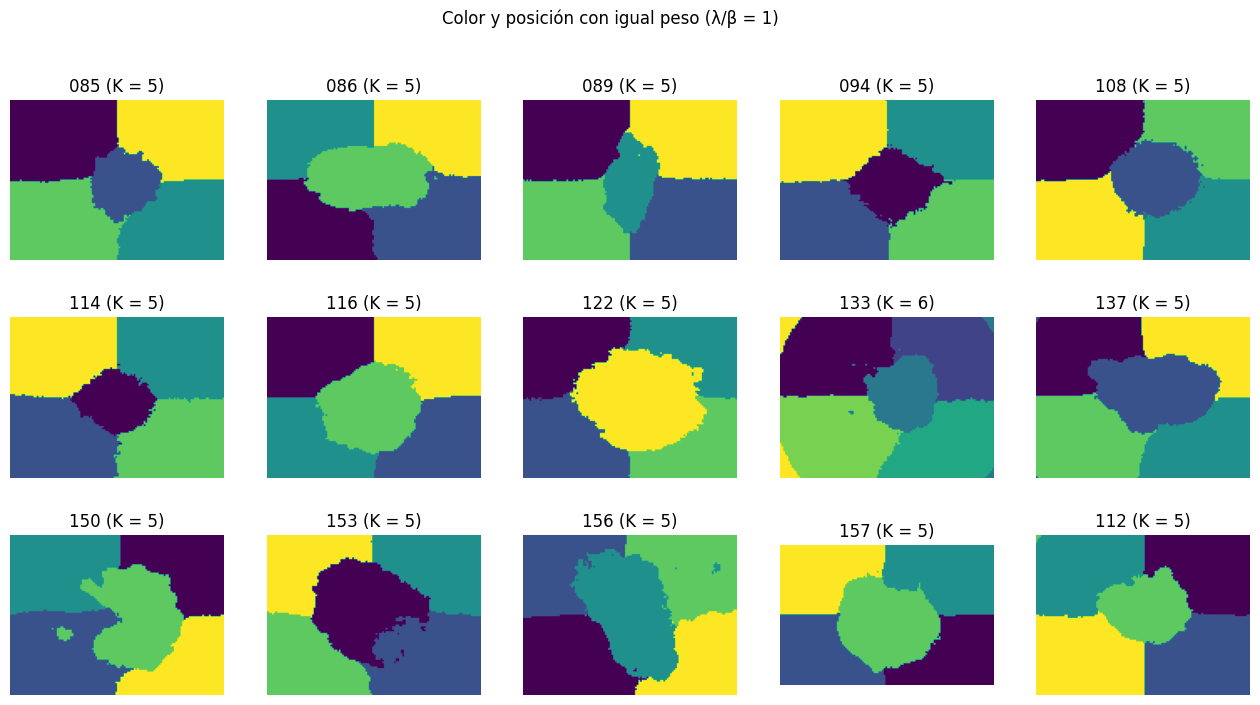

In [15]:
mostrar_grupos(1, 1, 'Color y posición con igual peso (λ/β = 1)')

#### Color y posición con igual peso ($\lambda/\beta = 1$, K = 5)

Con $\lambda/\beta = 1$ aparece una estructura muy regular en todas las imágenes: cuatro grupos dividen la imagen en cuadrantes aproximados y un quinto grupo ocupa la región central, compatible con la lesión.

1. **La piel se divide por posición y la lesión se separa por color.** La piel ocupa la mayor parte de la imagen y tiene un color relativamente homogéneo dentro de su cuadrante. Dentro de ella domina la posición, y K-medias la reparte en cuatro cuadrantes, igual que en la configuración de solo posición, donde la silueta elige K = 4. La lesión, en cambio, se diferencia de la piel en color y ocupa una zona compacta, por lo que conserva un grupo propio. Esto explica por qué la silueta elige K = 5 en casi todas las imágenes: cuatro parches espaciales de piel más la lesión.
2. **Desaparecen las esquinas oscuras y el ruido disperso.** Las esquinas que con solo color quedaban junto con la lesión ahora pertenecen a los cuadrantes de piel. Un píxel oscuro en una esquina se parece en color a la lesión, pero está lejos de ella en posición, y con este peso la posición decide. Por la misma razón, desaparecen los puntos dispersos alrededor de la lesión.
3. **ISIC_0000133 es la única imagen con K = 6.** Además de los cinco grupos habituales, aparece un grupo pequeño en la esquina inferior izquierda, que parece corresponder a la zona más oscura del viñeteo. Esta imagen era la que tenía el viñeteo más marcado con solo color, por lo que es posible que el contraste de esas esquinas sea suficiente para formar un grupo propio incluso con este peso de la posición.
4. **Las lesiones pequeñas pueden sobreestimarse.** En ISIC_0000114, la lesión más pequeña del conjunto, el grupo central es visiblemente más grande y con forma de rombo que la región obtenida con solo color. Este parece ser el costo de incluir la posición: puede producir falsos positivos alrededor de lesiones pequeñas.
5. **La heterogeneidad de la lesión se reduce, pero no desaparece.** En la lesión de la imágen de la tercera fila - tercera columna, y otras más, la mayoría de los huecos que dejaban las zonas claras de la lesión con solo color quedan ahora dentro del grupo de la lesión, aunque persisten algunos puntos en su parte inferior
6. **El número del grupo sigue siendo arbitrario.** El grupo de la lesión cambia de etiqueta entre imágenes, igual que con solo color.

En conclusión, la posición actúa como un regularizador espacial: elimina las esquinas oscuras y el ruido disperso que confundían a la agrupación por color, pero a cambio puede agrandar las lesiones pequeñas y suavizar sus bordes.

### 3.2 Requisitos del criterio

A partir de las dos exploraciones anteriores, el criterio de construcción de la máscara debe cumplir lo siguiente:

- **No depender del número del grupo.** La lesión debe identificarse a partir de características del grupo, como su color medio (la lesión es más oscura que la piel) o la ubicación de su centroide espacial.
- **Funcionar con cualquier K.** La silueta elige K = 2 con poco peso de la posición, K ≈ 5 con más peso y, en algunos casos, K = 4 o 6. El criterio debe ser una única regla que funcione en todos estos casos, sin saber de antemano qué K se eligió.
- **Manejar las esquinas oscuras sin eliminar lesiones cercanas al borde.** Con K = 2, el grupo más oscuro incluye las esquinas del viñeteo. Sin embargo, ISIC_0000156 muestra que la lesión puede llegar al borde, así que no conviene descartar sin más toda región que toque el borde.
- **Considerar la heterogeneidad de la lesión.** Las zonas claras dentro de la lesión pueden dejar huecos. Un posprocesamiento simple, como rellenar huecos, puede corregirlo.

### 3.3 Criterios propuestos

K-medias entrega una etiqueta por píxel, pero no dice cuál etiqueta es la lesión. Un criterio de construcción de la máscara es una regla automática que, a partir de las características de cada grupo, decide cuáles píxeles se marcan como lesión (1) y cuáles como piel o fondo (0).

Se proponen dos criterios, que se diferencian en la información que usan para identificar la lesión:

- **Criterio A: grupo más oscuro (solo color).** La lesión es el grupo cuyo color promedio es más oscuro. Después se aplica una limpieza básica: se rellenan los huecos y se eliminan las manchas muy pequeñas. Este criterio funciona como línea base, porque es la regla más simple que se desprende de la exploración de la sección 3.1.
- **Criterio B: puntaje de oscuridad y centralidad (color y ubicación).** Cada grupo recibe un puntaje que combina qué tan oscuro es y qué tan cerca del centro de la imagen están sus píxeles. Se elige el grupo con mayor puntaje y, de ese grupo, se conserva solo la mancha más cercana al centro. Finalmente se rellenan los huecos.

La comparación entre ambos permite responder si agregar la ubicación al criterio corrige los problemas observados en la sección 3.1, en particular las esquinas oscuras del viñeteo.

Ambos criterios calculan el color de cada grupo a partir de la imagen original y no de las características usadas por K-medias. Por eso funcionan con cualquier combinación de $\beta$ y $\lambda$.

#### Funciones auxiliares

**Nota:** Los cálculo numéricos de estas funciones auxiliares se determinaron con la ayuda de Claude a partir de los criterios propuestos inicialmente por los estudiantes y refinados por la misma herramienta.

Antes de definir los criterios se necesitan algunas herramientas.

**Luminancia.** Para decidir qué grupo es "más oscuro" hace falta un solo número por píxel que mida su brillo. La luminancia combina los tres canales con los pesos estándar de la recomendación ITU-R BT.601:

$$L = 0.299\,R + 0.587\,G + 0.114\,B$$

**Distancia al centro.** Para medir qué tan central es un píxel se calcula su distancia al centro de la imagen, usando las coordenadas normalizadas a [0, 1] igual que en la representación. El centro es el punto (0.5, 0.5) y la distancia máxima posible, desde el centro hasta una esquina, es $\sqrt{0.5^2 + 0.5^2} \approx 0.707$.

**Características de cada grupo.** Para cada grupo se calcula su área (porcentaje de píxeles de la imagen), su luminancia media y la distancia media de sus píxeles al centro. Se usa la distancia media de los píxeles y no la distancia del centroide del grupo, porque un grupo formado por las cuatro esquinas tiene su centroide justo en el centro de la imagen aunque ninguno de sus píxeles esté ahí.

**Regiones conectadas.** Un mismo grupo puede estar formado por varias manchas separadas: por ejemplo, la lesión y las cuatro esquinas. Una región conectada es una mancha de píxeles que se tocan entre sí. La función `ndimage.label` de SciPy numera cada mancha por separado, lo que permite medir el tamaño y la posición de cada una y decidir cuáles conservar.

**Área mínima.** Las manchas de menos del 1 % del área de la imagen (unos 120 píxeles en imágenes de 128 × 96) se consideran ruido: puntos sueltos, pelos o reflejos. Este valor está muy por debajo del tamaño de cualquier lesión del conjunto de ajuste, por lo que no debería eliminar lesiones reales.

In [19]:
from scipy import ndimage

AREA_MINIMA = 0.01          
DIST_MAX = np.sqrt(0.5)     

def luminancia(imagen):
    rgb = imagen / 255.0
    return 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]

def distancia_al_centro(forma):
    alto, ancho = forma
    I, J = np.meshgrid(np.arange(alto), np.arange(ancho), indexing='ij')
    return np.sqrt((J / (ancho - 1) - 0.5) ** 2 + (I / (alto - 1) - 0.5) ** 2)

def caracteristicas_grupos(imagen, etiquetas):
    lum = luminancia(imagen)
    dist = distancia_al_centro(etiquetas.shape)
    filas = []
    for g in np.unique(etiquetas):
        sel = etiquetas == g
        filas.append({'grupo': g, 'area_%': 100 * sel.mean(),
                      'luminancia': lum[sel].mean(), 'distancia_media': dist[sel].mean()})
    return pd.DataFrame(filas)

def eliminar_regiones_pequenas(mascara, area_minima=AREA_MINIMA):
    regiones, n = ndimage.label(mascara)
    if n == 0:
        return mascara
    ids = np.arange(1, n + 1)
    tamanos = ndimage.sum(mascara, regiones, ids) / mascara.size
    grandes = ids[tamanos >= area_minima]
    if len(grandes) == 0:
        grandes = [ids[np.argmax(tamanos)]]
    return np.isin(regiones, grandes)

def region_central(mascara, area_minima=AREA_MINIMA):
    regiones, n = ndimage.label(mascara)
    if n == 0:
        return mascara
    ids = np.arange(1, n + 1)
    tamanos = ndimage.sum(mascara, regiones, ids) / mascara.size
    centros = ndimage.center_of_mass(mascara, regiones, ids)   # (fila, columna) de cada mancha
    alto, ancho = mascara.shape
    distancias = np.array([np.hypot(c / (ancho - 1) - 0.5, f / (alto - 1) - 0.5) for f, c in centros])
    candidatas = np.where(tamanos >= area_minima)[0]
    if len(candidatas) == 0:
        candidatas = [np.argmax(tamanos)]
    elegida = min(candidatas, key=lambda i: distancias[i])
    return regiones == ids[elegida]

#### Criterio A: grupo más oscuro

En las imágenes dermatoscópicas, la lesión suele ser más oscura que la piel que la rodea. La exploración de la sección 3.1 lo confirma: con solo color, uno de los dos grupos siempre contiene la lesión, y es el grupo de píxeles oscuros. El criterio A traduce esa observación en una regla directa:

1. Calcular la luminancia media de cada grupo.
2. Marcar como lesión todos los píxeles del grupo con menor luminancia media.
3. Rellenar los huecos: si hay píxeles de piel completamente rodeados por lesión, se marcan como lesión. Esto corrige las zonas claras dentro de la lesión.
4. Eliminar las manchas que ocupan menos del 1 % de la imagen, que corresponden a puntos sueltos o pelos.

Este criterio no usa la ubicación de los grupos. Por eso se espera que falle cuando una zona oscura que no es lesión es lo bastante grande para sobrevivir a la limpieza, como las esquinas del viñeteo con solo color. También puede fallar si la silueta elige un K en el que el grupo más oscuro no es la lesión, por ejemplo si las esquinas forman un grupo propio.

In [16]:
def criterio_oscuridad(imagen, etiquetas):
    """Criterio A: el grupo más oscuro es la lesión, con relleno de huecos y eliminación de ruido."""
    car = caracteristicas_grupos(imagen, etiquetas)
    grupo = car.loc[car['luminancia'].idxmin(), 'grupo']
    mascara = etiquetas == grupo
    mascara = ndimage.binary_fill_holes(mascara)
    mascara = eliminar_regiones_pequenas(mascara)
    return mascara.astype(int)

#### Criterio B: puntaje de oscuridad y centralidad

El criterio B agrega una segunda observación de la sección 3.1: la lesión no solo es oscura, sino que además suele estar cerca del centro de la imagen, porque quien toma la foto centra el dermatoscopio sobre ella. En cambio, las esquinas del viñeteo son oscuras pero están lo más lejos posible del centro. Combinar ambas propiedades debería permitir distinguirlas.

**Paso 1. Puntaje de cada grupo.** Se calculan dos valores entre 0 y 1:

- **Oscuridad**: compara la luminancia del grupo con la de los demás grupos de la misma imagen. El grupo más oscuro recibe 1 y el más claro recibe 0:
$$\text{oscuridad} = \frac{L_{\max} - L_{\text{grupo}}}{L_{\max} - L_{\min}}$$
Se usa una escala relativa porque el brillo general cambia entre imágenes según la piel del paciente y la iluminación. Lo importante no es qué tan oscuro es un grupo en absoluto, sino qué tan oscuro es respecto a los demás.
- **Centralidad**: vale 1 si los píxeles del grupo están, en promedio, en el centro, y se acerca a 0 si están en las esquinas:
$$\text{centralidad} = 1 - \frac{\text{distancia media al centro}}{0.707}$$

El puntaje es la suma de ambos y se elige el grupo con el puntaje más alto. Se da el mismo peso a las dos propiedades porque no hay una razón previa para preferir una sobre la otra.

**Paso 2. Región central.** El grupo elegido puede contener varias manchas: la lesión y algunas esquinas, por ejemplo. De todas las manchas de al menos el 1 % del área, se conserva solo aquella cuyo centro está más cerca del centro de la imagen. A diferencia de eliminar todo lo que toca el borde, esta regla no descarta una lesión que llegue al borde, como en ISIC_0000156, siempre que siga siendo la mancha más central.

**Paso 3. Relleno de huecos**, igual que en el criterio A.

Este criterio también tiene limitaciones esperables; si la lesión está lejos del centro la centralidad la penaliza. A su vez, al conservar una sola mancha descarta regiones separadas que podrían ser parte de la lesión.

In [17]:
def puntajes_grupos(imagen, etiquetas):
    """Agrega a la tabla de cada grupo su oscuridad relativa, su centralidad y su puntaje."""
    car = caracteristicas_grupos(imagen, etiquetas)
    L = car['luminancia']
    rango = L.max() - L.min()
    car['oscuridad'] = (L.max() - L) / rango if rango > 0 else 1.0
    car['centralidad'] = 1 - car['distancia_media'] / DIST_MAX
    car['puntaje'] = car['oscuridad'] + car['centralidad']
    return car

def criterio_puntaje(imagen, etiquetas):
    """Criterio B: grupo con mayor oscuridad + centralidad, conservando su región más central."""
    car = puntajes_grupos(imagen, etiquetas)
    grupo = car.loc[car['puntaje'].idxmax(), 'grupo']
    mascara = etiquetas == grupo
    mascara = region_central(mascara)
    mascara = ndimage.binary_fill_holes(mascara)
    return mascara.astype(int)

#### Ejemplo de cálculo del puntaje

Para ver cómo decide el criterio B, se muestra la tabla de características y puntajes de ISIC_0000133 con $\lambda/\beta = 1$. Es la imagen donde la silueta eligió K = 6, con un grupo adicional que parece corresponder a la esquina oscura. En la tabla, el criterio A elige el grupo con menor `luminancia` y el criterio B elige el grupo con mayor `puntaje`.

In [20]:
def k_elegido(id_img, beta, lam):
    """K elegido por la silueta para una imagen y una combinación (β, λ)."""
    fila = mejor_k[(mejor_k['id'] == id_img) & (mejor_k['beta'] == beta) & (mejor_k['lam'] == lam)]
    return int(fila['k'].iloc[0])

id_ej = 'ISIC_0000133'
k_ej = k_elegido(id_ej, 1, 1)
puntajes_grupos(imagenes[id_ej], etiquetas_todas[(id_ej, 1, 1, k_ej)]).round(3)

,grupo,area_%,luminancia,distancia_media,oscuridad,centralidad,puntaje
0,0,22.697,0.611,0.394,0.094,0.443,0.537
1,1,19.019,0.635,0.442,0.048,0.376,0.423
2,2,12.590,0.376,0.173,0.549,0.756,1.305
3,3,19.735,0.660,0.439,0.000,0.379,0.379
4,4,23.910,0.595,0.381,0.126,0.461,0.587
5,5,2.051,0.142,0.641,1.000,0.093,1.093


**Lectura de la tabla.** Con K = 6, los seis grupos de ISIC_0000133 se pueden reconocer por sus características:

- **Grupos 0, 1, 3 y 4 (los cuatro cuadrantes de piel).** Ocupan cada uno entre 19 % y 24 % de la imagen, son claros (luminancia entre 0.60 y 0.66) y sus píxeles están lejos del centro (distancia media alrededor de 0.4). Sus puntajes son bajos, entre 0.38 y 0.59.
- **Grupo 2 (la lesión).** Ocupa 12.6 % de la imagen, cerca del 14.2 % que marca la referencia. Es oscuro (0.376) y central (distancia media 0.173), por lo que obtiene el puntaje más alto: 1.305.
- **Grupo 5 (la esquina oscura).** Ocupa solo 2 % de la imagen, pero es el grupo más oscuro de todos (0.142), incluso más que la lesión. Sus píxeles están casi en la esquina (distancia media 0.641, muy cerca del máximo de 0.707).

**Qué decide cada criterio.**

- El criterio A elige el grupo con menor luminancia: el grupo 5. Es decir, marca como lesión la esquina del viñeteo y deja fuera la lesión real.
- El criterio B elige el grupo con mayor puntaje: el grupo 2. El grupo 5 recibe la máxima oscuridad (1.000), pero su centralidad es casi nula (0.093). La lesión es menos oscura (0.549), pero mucho más central (0.756), y la suma la favorece.

Este ejemplo muestra por qué la ubicación es necesaria en el criterio: el color por sí solo no distingue la lesión de una sombra del dermatoscopio. Sin embargo, la ventaja de la lesión no es muy amplia (1.305 frente a 1.093). Si la lesión estuviera más lejos del centro o fuera más clara, el criterio B también podría equivocarse.

También se observa una debilidad de la escala relativa de oscuridad. Como la esquina es muy oscura, "estira" la escala, y la lesión, aunque es claramente más oscura que la piel, solo recibe 0.549.

#### Comparación visual de los criterios

Se aplican ambos criterios a cinco imágenes de ajuste que representan los casos observados en la sección 3.1: una separación limpia, una lesión pequeña con esquinas oscuras, el viñeteo más marcado, huecos dentro de la lesión y una lesión que llega cerca del borde con una mancha aislada. Se muestran las dos configuraciones exploradas: solo color y $\lambda/\beta = 1$. La máscara de referencia se incluye solo para comparar visualmente. La evaluación cuantitativa con Dice se hace en la actividad 4.

In [23]:
def comparar_criterios(ids, beta, lam, titulo):
    """Muestra, para cada imagen: original, grupos, máscara del criterio A, del criterio B y referencia."""
    fig, ax = plt.subplots(len(ids), 5, figsize=(15, 2.6 * len(ids)), squeeze=False)
    for fila, id_img in zip(ax, ids):
        k = k_elegido(id_img, beta, lam)
        img = imagenes[id_img]
        etiquetas = etiquetas_todas[(id_img, beta, lam, k)]
        fila[0].imshow(img);       fila[0].set_title(f'{id_img[-3:]}: original')
        fila[1].imshow(etiquetas); fila[1].set_title(f'Grupos (K = {k})')
        fila[2].imshow(criterio_oscuridad(img, etiquetas), cmap='gray', vmin=0, vmax=1); fila[2].set_title('Criterio A')
        fila[3].imshow(criterio_puntaje(img, etiquetas), cmap='gray', vmin=0, vmax=1);   fila[3].set_title('Criterio B')
        fila[4].imshow(mascaras[id_img], cmap='gray', vmin=0, vmax=1);                   fila[4].set_title('Referencia')
        for a in fila:
            a.axis('off')
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

ids_ejemplo = ['ISIC_0000085', 'ISIC_0000114', 'ISIC_0000133', 'ISIC_0000153', 'ISIC_0000156']

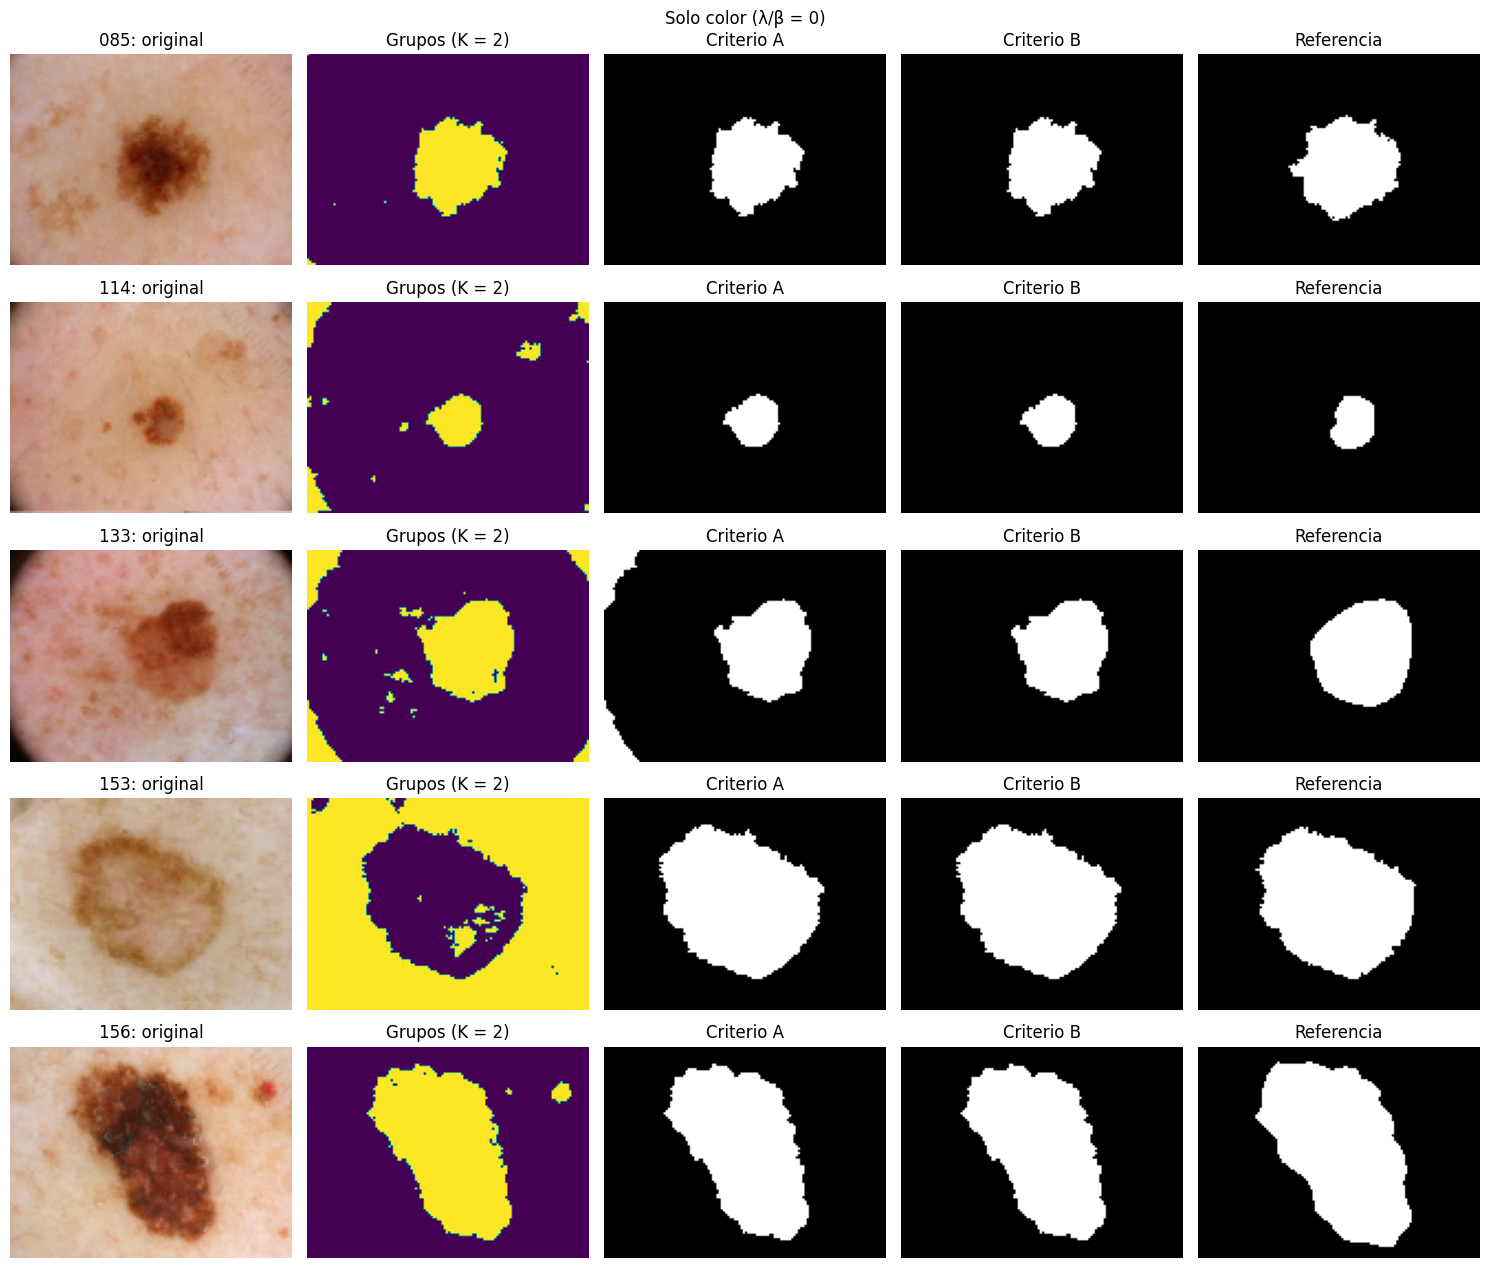

In [24]:
comparar_criterios(ids_ejemplo, 1, 0, 'Solo color (λ/β = 0)')

**Resultados con solo color ($\lambda/\beta = 0$, K = 2).** Con esta configuración, los dos criterios producen máscaras muy parecidas a la referencia en las cinco imágenes. Las diferencias entre ellos aparecen solo en la imagen con viñeteo fuerte.

- **ISIC_0000085 (separación limpia).** Ambos criterios coinciden y la forma es muy cercana a la referencia. La máscara es un poco más pequeña: deja fuera algunos bordes de la lesión, de color más claro, que el dermatólogo sí incluyó.
- **ISIC_0000114 (lesión pequeña con esquinas oscuras).** Ambos criterios aíslan bien la lesión. En el criterio A, las esquinas y las manchas sueltas desaparecen gracias al filtro de área mínima, porque cada una ocupa menos del 1 % de la imagen.
- **ISIC_0000133 (viñeteo fuerte).** Aquí está la diferencia entre criterios. El criterio A conserva la franja oscura del borde izquierdo, porque es lo bastante grande para superar el filtro de área. El criterio B la descarta, porque conserva solo la región más central. En ambos casos la lesión queda algo más pequeña que en la referencia, con una muesca en su lado izquierdo, donde la lesión es más clara.
- **ISIC_0000153 (huecos dentro de la lesión).** Los grupos muestran zonas claras dentro de la lesión, pero el relleno de huecos las corrige. Ambas máscaras quedan muy cercanas a la referencia.
- **ISIC_0000156 (lesión grande con una mancha aislada).** Ambos criterios eliminan la mancha aislada de la derecha. En la imagen original se ve que es un pequeño punto rojo, no parte de la lesión, así que eliminarla es correcto.

En resumen, con solo color el criterio B es igual o mejor que el A en todos los casos. El patrón general es que las máscaras tienden a quedar un poco más pequeñas que la referencia, porque los bordes claros de la lesión se parecen más a la piel que al centro oscuro.

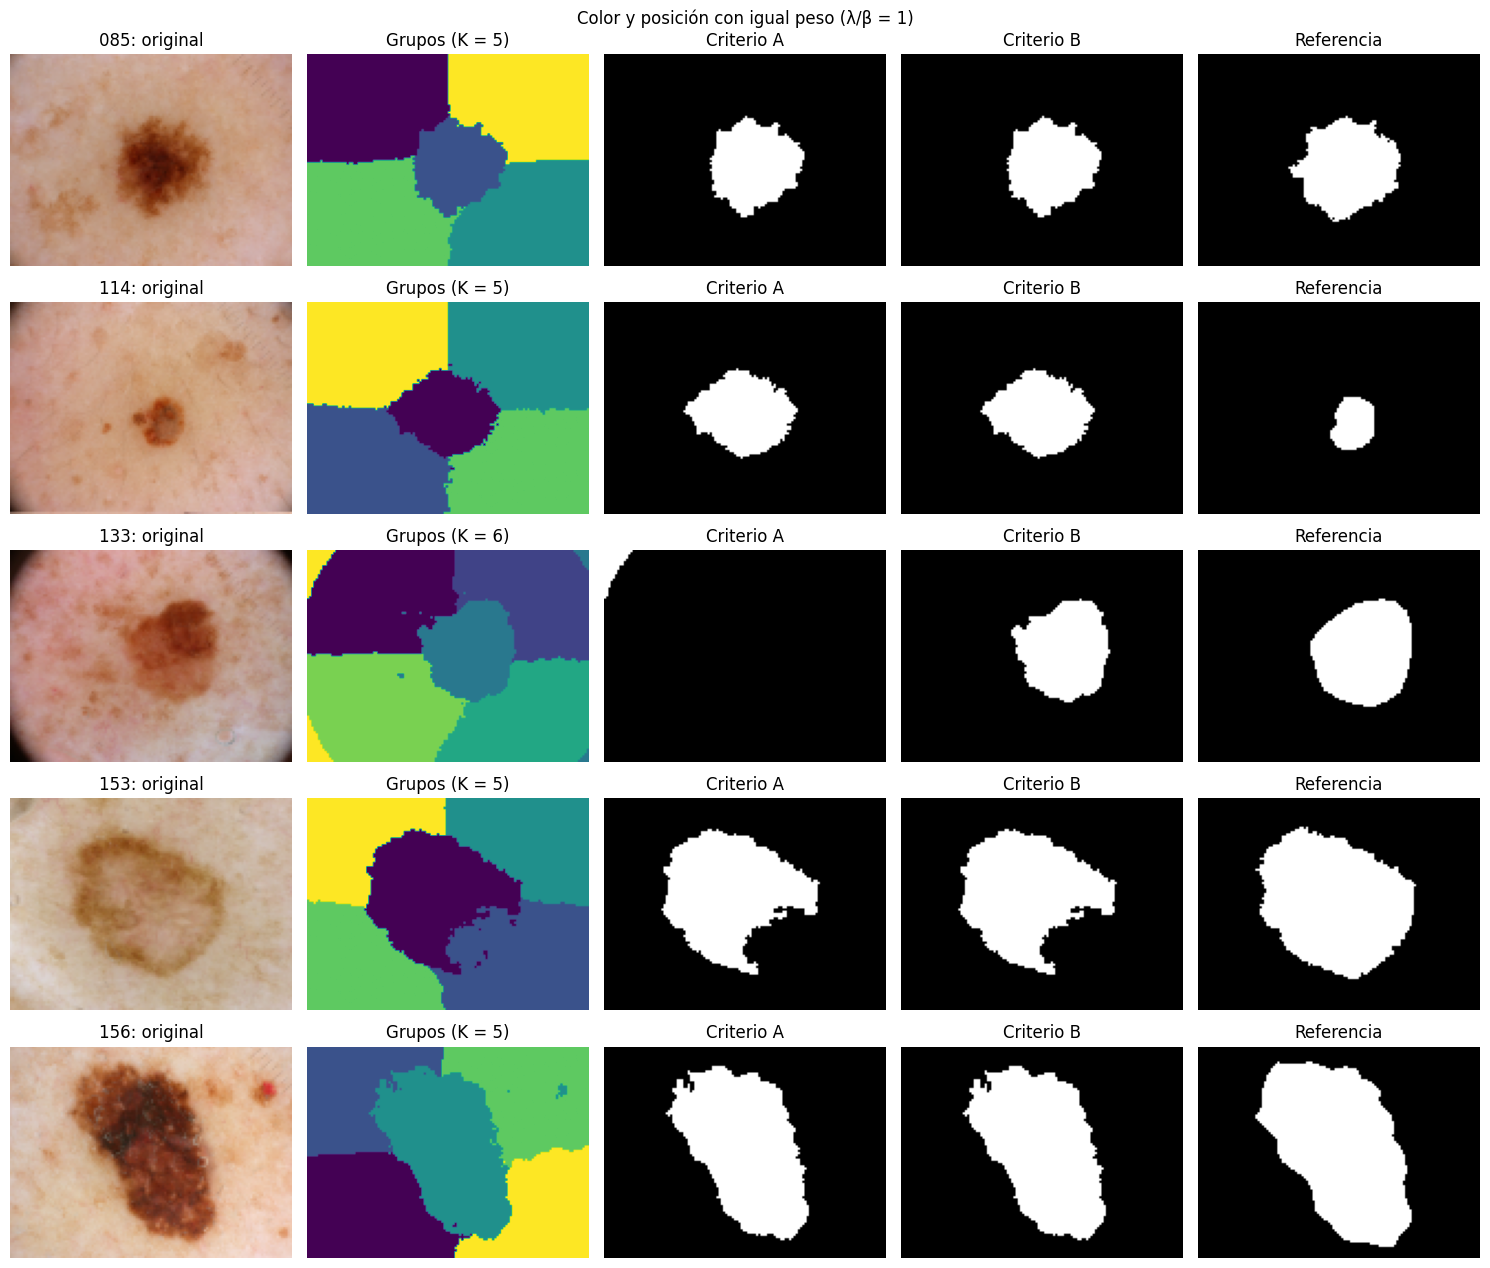

In [25]:
comparar_criterios(ids_ejemplo, 1, 1, 'Color y posición con igual peso (λ/β = 1)')

**Resultados con color y posición ($\lambda/\beta = 1$, K = 5 o 6).** Con esta configuración aparecen tres diferencias importantes respecto a solo color.

- **ISIC_0000133 (K = 6): el criterio A falla por completo.** Como se vio en la tabla, el grupo más oscuro es la esquina superior izquierda, así que el criterio A entrega una máscara casi vacía, con solo un pequeño fragmento en esa esquina. El criterio B elige la lesión y produce prácticamente la misma máscara que con solo color. Es la diferencia más clara entre los dos criterios en toda la exploración.
- **ISIC_0000114: la lesión pequeña se sobreestima.** Ambos criterios producen una región en forma de rombo varias veces más grande que la lesión de referencia. Esto confirma lo anticipado en la sección 3.1. Con la posición, los píxeles de piel cercanos al centro quedan más cerca del grupo de la lesión que de los cuadrantes, y se asignan a la lesión. Ningún criterio puede corregir este error, porque está en los grupos: la lesión y la piel que la rodea quedaron en el mismo grupo. Con solo color, la máscara de esta imagen era mucho más precisa.
- **ISIC_0000153: la lesión queda partida entre dos grupos.** La parte inferior derecha de la lesión, de color más claro, quedó asignada al cuadrante de piel inferior derecho. Ambos criterios eligen un solo grupo, así que esa parte se pierde. El relleno de huecos no la recupera, porque no es un hueco cerrado: el faltante se abre hacia afuera de la lesión. Con solo color, esta imagen salía casi perfecta.

En ISIC_0000085 e ISIC_0000156 los resultados son prácticamente iguales a los de solo color.

En resumen, en estas cinco imágenes, agregar la posición a la agrupación no mejoró ninguna máscara y empeoró dos (ISIC_0000114 y 0000153). La posición resolvía el problema de las esquinas con solo color, pero el criterio B ya lo resuelve por su cuenta. Además, la posición introduce dos errores nuevos: agranda las lesiones pequeñas y puede partir una lesión heterogénea entre varios grupos.

### 3.4 Conclusiones de la sección

- **El criterio B es más robusto que el criterio A.** En todos los casos observados obtiene un resultado igual o mejor. La diferencia es decisiva cuando una zona oscura que no es lesión forma un grupo propio (ISIC_0000133 con K = 6) o es lo bastante grande para sobrevivir al filtro de área (ISIC_0000133 con K = 2).
- **El posprocesamiento es útil.** El relleno de huecos corrige la heterogeneidad del color dentro de la lesión (ISIC_0000153 con solo color), y el filtro de área elimina ruido y manchas pequeñas como el punto rojo de ISIC_0000156.
- **Hay errores que ningún criterio puede corregir.** Cuando la lesión y la piel quedan en el mismo grupo o la lesión queda repartida en varios grupos, el error viene de la agrupación y no del criterio. Elegir un solo grupo no es suficiente en esos casos.
- **Con este criterio, la posición parece aportar poco.** En estas cinco imágenes, solo color dio máscaras iguales o mejores que $\lambda/\beta = 1$.

Estas conclusiones se basan en solo cinco imágenes y dos combinaciones de $\beta$ y $\lambda$. Por eso ambos criterios se evalúan de forma sistemática en la actividad 4, con el Dice promedio sobre las 15 imágenes de ajuste y las 10 combinaciones, antes de elegir la configuración final.